# Prescribe individual coordinates and change the loading mode

This notebook uses the same nine polygons with four different boundary conditions:

1. Compression with clamped upper and lower grips.
2. Compression with horizontal sliding and free grip rotation.
3. The sliding case with **only polygon 4's angle** prescribed to a chosen value.
4. Shear: the upper grip moves horizontally while the lower grip stays fixed.

You will construct the masks and displacement paths explicitly, verify every prescribed coordinate, and compare the responses. The companion `boundary_conditions.py` runs all four cases and saves figures and numerical results.

Install the package first using the README instructions. Select that Python environment as the notebook kernel. Run this notebook from either the repository root or its `examples/` directory.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
from types import SimpleNamespace

import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

import rotating_polygons as rp
from rotating_polygons.plotting import plot_geometry

# Import only plotting/check helpers from the adjacent example script.
# Geometry, boundary masks, initialization, and simulation are explicit below.
examples_dir = Path.cwd() / "examples"
if not (examples_dir / "boundary_conditions.py").is_file():
    examples_dir = Path.cwd()
if not (examples_dir / "boundary_conditions.py").is_file():
    raise RuntimeError("Run from the repository root or its examples directory.")
sys.path.insert(0, str(examples_dir))
from boundary_conditions import (  # noqa: E402 — after locating the companion script
    CASE_LABELS,
    label_polygons,
    plot_masks,
    plot_responses,
)

# Enable double precision before creating geometry or asking for tight residuals.
jax.config.update("jax_enable_x64", True)

## 1. Read the polygon IDs and coordinate array

The state array has shape `(n_polygons, 3)`. Its columns are `x`, `y`, and the counterclockwise angle `theta` in radians. For example:

- `q[4, 0]`: horizontal center coordinate of polygon 4.
- `q[4, 1]`: vertical center coordinate of polygon 4.
- `q[4, 2]`: rotation angle of polygon 4.

`square_grid(3, 3)` numbers polygons from left to right, then bottom to top. The small vertex offsets below break exact square symmetry so that rotational response is visible. They change the polygon shapes, not their centers or connectivity.

State shape: (9, 3)
Polygon IDs, shown from top row to bottom row:
[[6 7 8]
 [3 4 5]
 [0 1 2]]
Polygon 4 reference coordinates: [1. 1. 0.]


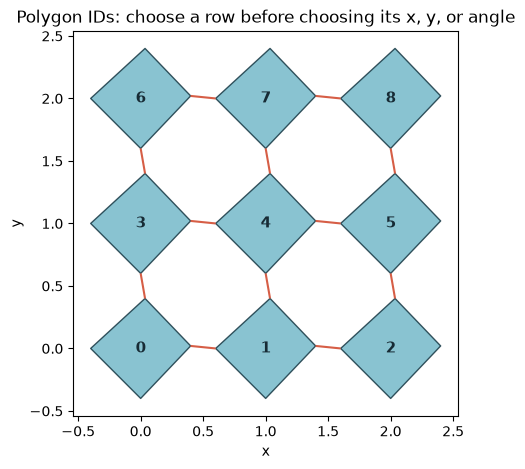

In [2]:
geometry = rp.square_grid(3, 3, spacing=1.0, hinge_gap=0.2)
q = np.asarray(geometry.reference_state)  # q[id] = [center_x, center_y, angle]
print("State shape:", q.shape)
print("Polygon IDs, shown from top row to bottom row:")
print(np.arange(9).reshape(3, 3)[::-1])
print("Polygon 4 reference coordinates:", q[4])

# Each polygon's local vertices are ordered right, up, left, down.
offsets = jnp.zeros((4, 2))
offsets = offsets.at[1, 0].set(0.035)  # move the upper corner horizontally
offsets = offsets.at[0, 1].set(0.020)  # move the right corner vertically
vertices = geometry.vertices + jnp.tile(offsets, (geometry.n_polygons, 1))

fig, ax = plt.subplots(figsize=(5, 5))
plot_geometry(geometry, vertices=vertices, ax=ax)
label_polygons(ax, q)
ax.set_title("Polygon IDs: choose a row before choosing its x, y, or angle")
plt.show()

## 2. Clamped compression

A mask entry equal to `True` means **prescribed**, which includes coordinates that move. An entry equal to `False` is an unknown found by energy minimization.

The default helper clamps all three coordinates on the lower and upper rows. The upper row's vertical coordinates follow `y_top = y_top_reference - epsilon * H`; the lower row stays still. Compression strain `epsilon` is positive.

In [3]:
clamped = rp.compression_boundary(geometry)

# IDs 0, 1, 2 form the bottom row; IDs 6, 7, 8 form the top row.
print("Bottom polygon 0 mask [x, y, angle]:", np.asarray(clamped.fixed_mask[0]))
print("Top polygon 6 mask [x, y, angle]:", np.asarray(clamped.fixed_mask[6]))
print("Top polygon 6 displacement per unit compression:", np.asarray(clamped.strain_direction[6]))
print("Middle polygon 4 mask:", np.asarray(clamped.fixed_mask[4]))

# Top y is prescribed AND moving. Its mask must therefore be True.
assert bool(clamped.fixed_mask[6, 1])
assert float(clamped.strain_direction[6, 1]) == -clamped.height

Bottom polygon 0 mask [x, y, angle]: [ True  True  True]
Top polygon 6 mask [x, y, angle]: [ True  True  True]
Top polygon 6 displacement per unit compression: [ 0. -2.  0.]
Middle polygon 4 mask: [False False False]


## 3. Sliding grips and free rotation

Release horizontal grip motion and grip rotation independently. The helper keeps one lower `x` coordinate pinned to remove rigid horizontal translation. Every grip `y` coordinate remains prescribed; all angles are free.

This case changes supports without changing the polygon geometry, ligament rest data, material parameters, or applied compression values.

In [4]:
sliding = rp.compression_boundary(
    geometry,
    clamp_horizontal=False,  # all grip x coordinates except one lower x pin are free
    clamp_rotations=False,  # grip angles are free to respond to the loading
)
print("Sliding case: polygon 0 mask:", np.asarray(sliding.fixed_mask[0]))
print("Sliding case: polygon 1 mask:", np.asarray(sliding.fixed_mask[1]))
print("Sliding case: polygon 6 mask:", np.asarray(sliding.fixed_mask[6]))

# No rotational coordinate is prescribed in this case.
assert not np.asarray(sliding.fixed_mask[:, 2]).any()

Sliding case: polygon 0 mask: [ True  True False]
Sliding case: polygon 1 mask: [False  True False]
Sliding case: polygon 6 mask: [False  True False]


## 4. Fix exactly one interior degree of freedom

Start from the sliding case and set `fixed_mask[4, 2] = True`. Polygon 4's `x` and `y` coordinates remain free.

The prescribed value is taken from **`BoundaryConditions.reference_state`**. Here it is `0.015` radians. The strain direction at `[4, 2]` remains zero, so that angle stays constant throughout loading.

This boundary target is distinct from the elastic reference geometry. We keep the original rest angles when initializing the material, so prescribing a nonzero angle can create reactions even at zero compression. To pin the original angle instead, use `q[4, 2]` as the target. Setting a numerical initial guess alone does not fix a degree of freedom; the mask does.

In [5]:
# Copy the mask: do not alter the sliding case while constructing a new one.
center_mask = np.array(sliding.fixed_mask, copy=True)
center_mask[4, 2] = True  # only the angle of polygon 4 is prescribed

# Change the boundary target, while keeping geometry.reference_state unchanged.
center_target = np.array(sliding.reference_state, copy=True)
center_target[4, 2] = 0.015  # radians; use q[4, 2] to hold its original angle

center_angle = rp.BoundaryConditions(
    reference_state=center_target,
    fixed_mask=center_mask,
    strain_direction=sliding.strain_direction,  # same top-y compression drive
    height=sliding.height,
    width=sliding.width,
)
assert np.array_equal(np.asarray(center_angle.fixed_mask[4]), [False, False, True])
assert float(center_angle.strain_direction[4, 2]) == 0.0
print("Polygon 4 mask [x, y, angle]:", np.asarray(center_angle.fixed_mask[4]))
print("Polygon 4 angle target:", float(center_angle.reference_state[4, 2]), "rad")

Polygon 4 mask [x, y, angle]: [False False  True]
Polygon 4 angle target: 0.015 rad


To prescribe a particular horizontal coordinate instead, the same pattern is:

```python
fixed = np.array(sliding.fixed_mask, copy=True)
target = np.array(sliding.reference_state, copy=True)
fixed[4, 0] = True       # prescribe polygon 4's x coordinate
target[4, 0] = q[4, 0]  # hold it at its original horizontal position
```

Pass those arrays to a new `BoundaryConditions` object. Choose column `1` for a vertical coordinate. To drive a prescribed coordinate rather than hold it constant, give that entry a nonzero displacement in `strain_direction`. All nonzero drive entries must also be marked `True` in the mask.

## 5. Construct a shear loading path

For simple shear, clamp the lower row and prescribe the upper row's horizontal displacement as `gamma * H`. The upper row's `y` coordinates and angles stay fixed, so the grips remain parallel.

The API calls its path parameter `strain`, but here that parameter is **shear strain `gamma`**, not compression `epsilon`. The corresponding measurement is `dE/dgamma / (H * W * thickness)`, which is the nominal shear stress. Positive shear drives the upper grip to the right.

In [6]:
bottom = np.isclose(q[:, 1], q[:, 1].min())  # IDs 0, 1, 2
top = np.isclose(q[:, 1], q[:, 1].max())  # IDs 6, 7, 8

shear_mask = np.zeros_like(q, dtype=bool)
shear_mask[bottom, :] = True  # bottom x, y, angle are held at their targets
shear_mask[top, :] = True  # top x moves; top y and angle are held constant

shear_direction = np.zeros_like(q)
shear_direction[top, 0] = clamped.height  # x_top = x_top_reference + gamma * H
# No y or angle entry is driven: those prescribed targets remain constant.

shear = rp.BoundaryConditions(
    reference_state=q,
    fixed_mask=shear_mask,
    strain_direction=shear_direction,
    height=clamped.height,
    width=clamped.width,
)
print("Top polygon 6 displacement per unit shear:", np.asarray(shear.strain_direction[6]))

Top polygon 6 displacement per unit shear: [2. 0. 0.]


## 6. Initialize the material and inspect all four masks

Initialization computes the rest data once for the chosen shape. All four cases below use that same initialized material. The mask plot separates free coordinates, constant prescribed targets, and moving prescribed targets.

Clamped compression: 9 free coordinates
Sliding grips, free rotation: 20 free coordinates
Sliding + polygon 4 angle prescribed: 19 free coordinates
Simple shear: 9 free coordinates


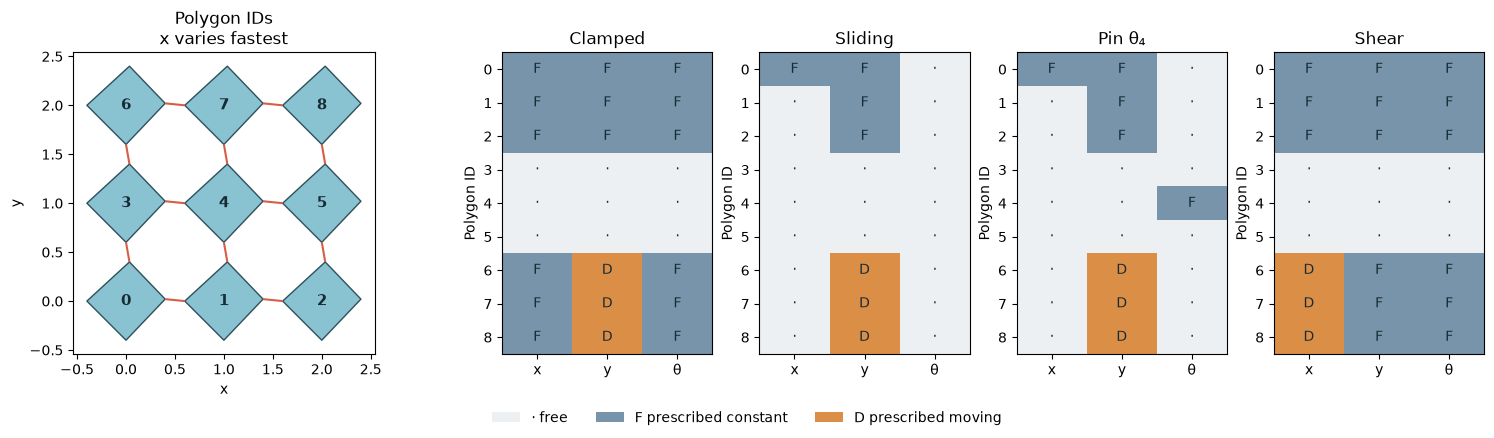

In [7]:
reference = rp.initialize(geometry, vertices)  # unchanged elastic rest geometry
boundaries = {
    "clamped": clamped,
    "sliding": sliding,
    "center_angle": center_angle,
    "shear": shear,
}

for name, boundary in boundaries.items():
    print(f"{CASE_LABELS[name]}: {boundary.free_indices.size} free coordinates")
plot_masks(geometry, reference, boundaries)
plt.show()

## 7. Solve and verify every prescribed coordinate

Use the same finite-ligament energy and BFGS settings for all cases. The array of load values represents `epsilon` for the three compression cases and `gamma` for the shear case.

`check_convergence()` rejects any failed equilibrium. The additional array assertion checks **every prescribed `x`, `y`, and angle at every loading step**, including the moving grip targets.

In [8]:
material = rp.PotentialParameters(stretching=1.0, shearing=0.1, bending=0.02, contact=40.0)
potential = rp.make_potential(geometry, material, model="finite_hinge")
options = rp.QuasistaticOptions(method="bfgs", tolerance=1e-9, max_iterations=700)
loading_values = jnp.linspace(0.0, 0.04, 9)  # absolute epsilon or gamma values

cases = {}
for name, boundary in boundaries.items():
    simulate = rp.make_quasistatic_solver(geometry, boundary, potential, options)
    solution = simulate(reference, loading_values).check_convergence()

    # Evaluate the prescribed path and compare ALL entries where mask == True.
    expected = np.asarray(jax.vmap(boundary.state_at)(loading_values))
    mask = np.asarray(boundary.fixed_mask)
    np.testing.assert_allclose(
        np.asarray(solution.states)[:, mask], expected[:, mask], atol=1e-12, rtol=0
    )

    # This contracts reactions with this case's own loading direction.
    # The shear case therefore produces shear stress, not compression stress.
    measure = rp.make_stress_measurement(potential, boundary, thickness=1.0)
    stress = measure(solution.states, reference)
    cases[name] = SimpleNamespace(boundary=boundary, solution=solution, stress=stress)
    print(
        f"{CASE_LABELS[name]}: max residual = "
        f"{float(jnp.max(solution.residuals)):.3g}; prescribed coordinates verified"
    )

# A directly readable check of the single interior angle constraint.
np.testing.assert_allclose(
    cases["center_angle"].solution.states[:, 4, 2], 0.015, atol=1e-12, rtol=0
)

Clamped compression: max residual = 8.19e-10; prescribed coordinates verified


Sliding grips, free rotation: max residual = 6.61e-10; prescribed coordinates verified


Sliding + polygon 4 angle prescribed: max residual = 9.93e-10; prescribed coordinates verified


Simple shear: max residual = 5.28e-10; prescribed coordinates verified


## 8. Compare responses and inspect the deformation

The compression curves differ because the allowed motions differ. The second panel confirms that the interior angle is constant only when it is prescribed. The shear curve and deformed shear geometry are shown separately because they use a different loading mode and work-conjugate stress.

These are dimensionally consistent model units with unit thickness. The shape is deliberately small for an executable tutorial. Quantitative predictions require the appropriate material coefficients, dimensions, and thickness.

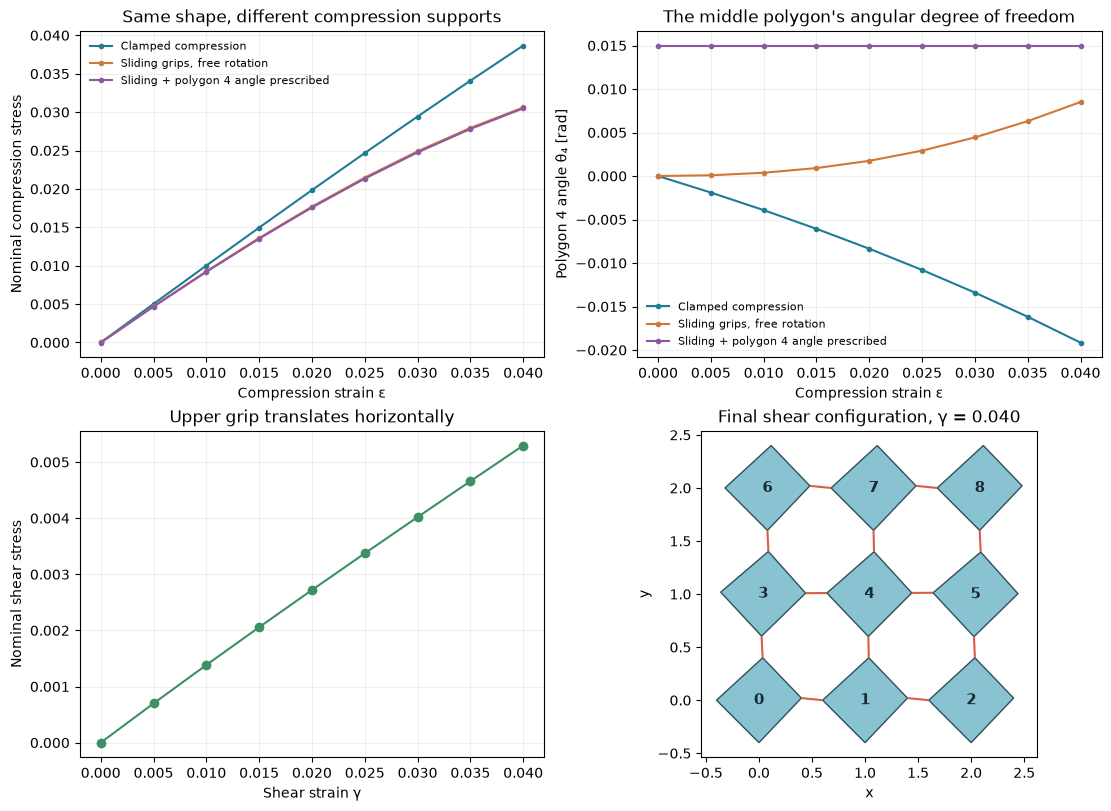

Polygon 4 final [x, y, angle], with its angle prescribed:
[0.95135018 0.96025059 0.015     ]
Its x and y were solved; only its angle was fixed.


In [9]:
response_figure = plot_responses(geometry, reference, cases, loading_values)
plt.show()

# Free coordinates are not expected to remain at their reference values.
print("Polygon 4 final [x, y, angle], with its angle prescribed:")
print(np.asarray(cases["center_angle"].solution.states[-1, 4]))
print("Its x and y were solved; only its angle was fixed.")

## Try a different support

Change one mask entry, rebuild that `BoundaryConditions`, and rerun the solver cells. Useful experiments include clamping only grip rotation, pinning the middle polygon's `x` coordinate, or prescribing a small rotation proportional to the loading parameter.

Keep enough supports to remove rigid translation and rotation modes. Do not identify a degree of freedom as fixed merely because it happened not to move in a symmetric solution; inspect the mask and assert the prescribed path.

For script output files, run:

```bash
python examples/boundary_conditions.py --output outputs/boundaries
```

The files contain the mask figure, response figure, complete state trajectories, stresses, residuals, and prescribed displacement directions.